In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
DATA_PATH = r"C:\Users\Akshay\OneDrive\Desktop\DMV & ML Practical\DMV Practical\DMV 4\RealEstate_Prices.csv"
df = pd.read_csv(DATA_PATH)
df.head()

,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,...,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
0,7129300520,20141013T000000,221900.0,3,1.00,1180,5650,1.0,0,0,...,7,1180,0,1955,0,98178,47.5112,-122.257,1340,5650
1,6414100192,20141209T000000,538000.0,3,2.25,2570,7242,2.0,0,0,...,7,2170,400,1951,1991,98125,47.7210,-122.319,1690,7639
2,5631500400,20150225T000000,180000.0,2,1.00,770,10000,1.0,0,0,...,6,770,0,1933,0,98028,47.7379,-122.233,2720,8062
3,2487200875,20141209T000000,604000.0,4,3.00,1960,5000,1.0,0,0,...,7,1050,910,1965,0,98136,47.5208,-122.393,1360,5000
4,1954400510,20150218T000000,510000.0,3,2.00,1680,8080,1.0,0,0,...,8,1680,0,1987,0,98074,47.6168,-122.045,1800,7503


In [3]:
print("Dataset Shape:", df.shape)
print("\nColumn Names:")
print(df.columns.tolist())
print("\nDataset Information:")
df.info()

Dataset Shape: (21613, 21)

Column Names:
['id', 'date', 'price', 'bedrooms', 'bathrooms', 'sqft_living', 'sqft_lot', 'floors', 'waterfront', 'view', 'condition', 'grade', 'sqft_above', 'sqft_basement', 'yr_built', 'yr_renovated', 'zipcode', 'lat', 'long', 'sqft_living15', 'sqft_lot15']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21613 entries, 0 to 21612
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   id             21613 non-null  int64  
 1   date           21613 non-null  object 
 2   price          21613 non-null  float64
 3   bedrooms       21613 non-null  int64  
 4   bathrooms      21613 non-null  float64
 5   sqft_living    21613 non-null  int64  
 6   sqft_lot       21613 non-null  int64  
 7   floors         21613 non-null  float64
 8   waterfront     21613 non-null  int64  
 9   view           21613 non-null  int64  
 10  condition      21613 non-null  int64  
 11  grad

In [4]:
print("Missing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

Missing Values:
id               0
date             0
price            0
bedrooms         0
bathrooms        0
sqft_living      0
sqft_lot         0
floors           0
waterfront       0
view             0
condition        0
grade            0
sqft_above       0
sqft_basement    0
yr_built         0
yr_renovated     0
zipcode          0
lat              0
long             0
sqft_living15    0
sqft_lot15       0
dtype: int64

Duplicate Rows: 0


In [5]:
df = df.drop_duplicates()
df = df.dropna()

print("Dataset Shape After Cleaning:", df.shape)
print("Missing Values After Cleaning:")
print(df.isnull().sum().sum())

Dataset Shape After Cleaning: (21613, 21)
Missing Values After Cleaning:
0


In [6]:
df.describe()

,id,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
count,2.161300e+04,2.161300e+04,21613.000000,21613.000000,21613.000000,2.161300e+04,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000
mean,4.580302e+09,5.400881e+05,3.370842,2.114757,2079.899736,1.510697e+04,1.494309,0.007542,0.234303,3.409430,7.656873,1788.390691,291.509045,1971.005136,84.402258,98077.939805,47.560053,-122.213896,1986.552492,12768.455652
std,2.876566e+09,3.671272e+05,0.930062,0.770163,918.440897,4.142051e+04,0.539989,0.086517,0.766318,0.650743,1.175459,828.090978,442.575043,29.373411,401.679240,53.505026,0.138564,0.140828,685.391304,27304.179631
min,1.000102e+06,7.500000e+04,0.000000,0.000000,290.000000,5.200000e+02,1.000000,0.000000,0.000000,1.000000,1.000000,290.000000,0.000000,1900.000000,0.000000,98001.000000,47.155900,-122.519000,399.000000,651.000000
25%,2.123049e+09,3.219500e+05,3.000000,1.750000,1427.000000,5.040000e+03,1.000000,0.000000,0.000000,3.000000,7.000000,1190.000000,0.000000,1951.000000,0.000000,98033.000000,47.471000,-122.328000,1490.000000,5100.000000
50%,3.904930e+09,4.500000e+05,3.000000,2.250000,1910.000000,7.618000e+03,1.500000,0.000000,0.000000,3.000000,7.000000,1560.000000,0.000000,1975.000000,0.000000,98065.000000,47.571800,-122.230000,1840.000000,7620.000000
75%,7.308900e+09,6.450000e+05,4.000000,2.500000,2550.000000,1.068800e+04,2.000000,0.000000,0.000000,4.000000,8.000000,2210.000000,560.000000,1997.000000,0.000000,98118.000000,47.678000,-122.125000,2360.000000,10083.000000
max,9.900000e+09,7.700000e+06,33.000000,8.000000,13540.000000,1.651359e+06,3.500000,1.000000,4.000000,5.000000,13.000000,9410.000000,4820.000000,2015.000000,2015.000000,98199.000000,47.777600,-121.315000,6210.000000,871200.000000


In [7]:
df.columns = df.columns.str.strip().str.lower().str.replace(" ", "_")
print(df.columns.tolist())

['id', 'date', 'price', 'bedrooms', 'bathrooms', 'sqft_living', 'sqft_lot', 'floors', 'waterfront', 'view', 'condition', 'grade', 'sqft_above', 'sqft_basement', 'yr_built', 'yr_renovated', 'zipcode', 'lat', 'long', 'sqft_living15', 'sqft_lot15']


In [8]:
numeric_columns = df.select_dtypes(include=np.number).columns
categorical_columns = df.select_dtypes(include="object").columns

print("Numerical Columns:")
print(numeric_columns.tolist())

print("\nCategorical Columns:")
print(categorical_columns.tolist())

Numerical Columns:
['id', 'price', 'bedrooms', 'bathrooms', 'sqft_living', 'sqft_lot', 'floors', 'waterfront', 'view', 'condition', 'grade', 'sqft_above', 'sqft_basement', 'yr_built', 'yr_renovated', 'zipcode', 'lat', 'long', 'sqft_living15', 'sqft_lot15']

Categorical Columns:
['date']


In [9]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()

for col in categorical_columns:
    df[col] = le.fit_transform(df[col].astype(str))

print(df.head())
print("\nData Types After Encoding:")
print(df.dtypes)

           id  date     price  bedrooms  bathrooms  sqft_living  sqft_lot  \
0  7129300520   164  221900.0         3       1.00         1180      5650   
1  6414100192   220  538000.0         3       2.25         2570      7242   
2  5631500400   290  180000.0         2       1.00          770     10000   
3  2487200875   220  604000.0         4       3.00         1960      5000   
4  1954400510   283  510000.0         3       2.00         1680      8080   

   floors  waterfront  view  ...  grade  sqft_above  sqft_basement  yr_built  \
0     1.0           0     0  ...      7        1180              0      1955   
1     2.0           0     0  ...      7        2170            400      1951   
2     1.0           0     0  ...      6         770              0      1933   
3     1.0           0     0  ...      7        1050            910      1965   
4     1.0           0     0  ...      8        1680              0      1987   

   yr_renovated  zipcode      lat     long  sqft_living1

In [10]:
correlation = df.corr()

print(correlation)

                     id      date     price  bedrooms  bathrooms  sqft_living  \
id             1.000000  0.005367 -0.016762  0.001286   0.005160    -0.012258   
date           0.005367  1.000000 -0.004649 -0.016964  -0.034481    -0.034570   
price         -0.016762 -0.004649  1.000000  0.308350   0.525138     0.702035   
bedrooms       0.001286 -0.016964  0.308350  1.000000   0.515884     0.576671   
bathrooms      0.005160 -0.034481  0.525138  0.515884   1.000000     0.754665   
sqft_living   -0.012258 -0.034570  0.702035  0.576671   0.754665     1.000000   
sqft_lot      -0.132109  0.006361  0.089661  0.031703   0.087740     0.172826   
floors         0.018525 -0.022395  0.256794  0.175429   0.500653     0.353949   
waterfront    -0.002721  0.001544  0.266369 -0.006582   0.063744     0.103818   
view           0.011592 -0.001837  0.397293  0.079532   0.187737     0.284611   
condition     -0.023783 -0.050755  0.036362  0.028472  -0.124982    -0.058753   
grade          0.008130 -0.0

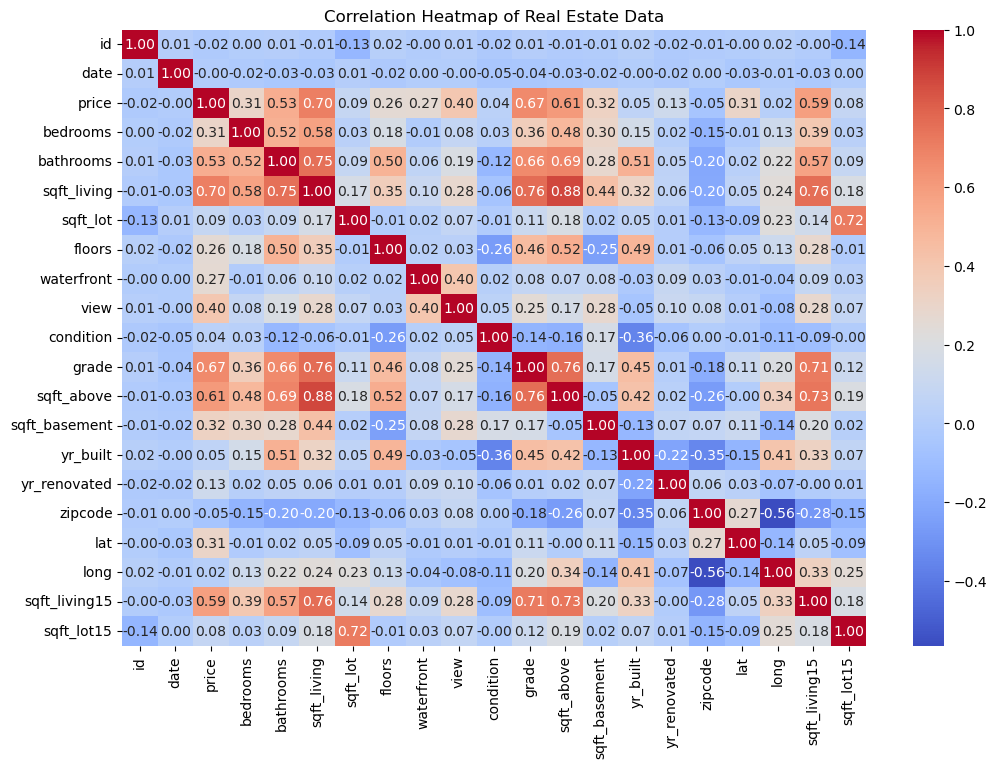

In [11]:
plt.figure(figsize=(12, 8))
sns.heatmap(df.corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap of Real Estate Data")
plt.show()

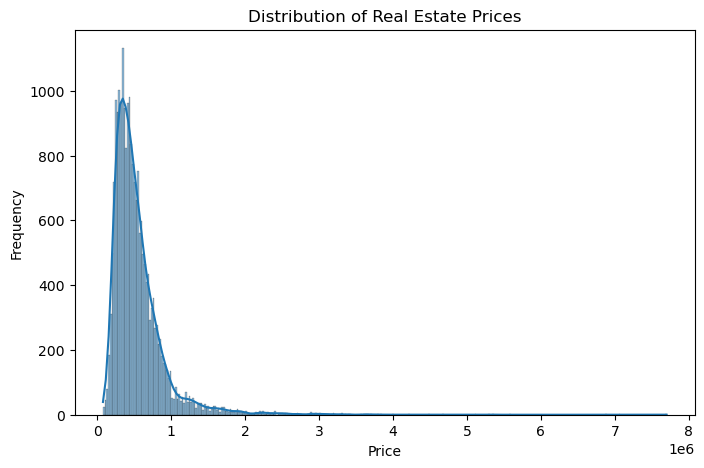

In [12]:
price_column = [col for col in df.columns if "price" in col.lower()][0]

plt.figure(figsize=(8, 5))
sns.histplot(df[price_column], kde=True)
plt.title("Distribution of Real Estate Prices")
plt.xlabel("Price")
plt.ylabel("Frequency")
plt.show()

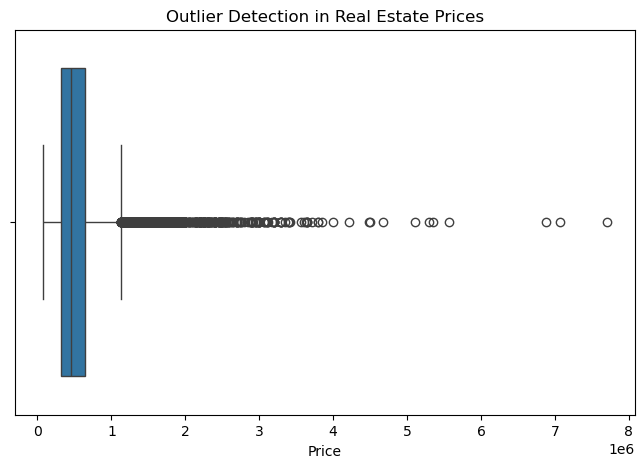

In [13]:
plt.figure(figsize=(8, 5))
sns.boxplot(x=df[price_column])
plt.title("Outlier Detection in Real Estate Prices")
plt.xlabel("Price")
plt.show()

In [14]:
Q1 = df[price_column].quantile(0.25)
Q3 = df[price_column].quantile(0.75)
IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

df = df[(df[price_column] >= lower_limit) & (df[price_column] <= upper_limit)]

print("Dataset Shape After Outlier Removal:", df.shape)

Dataset Shape After Outlier Removal: (20467, 21)


In [15]:
print("Final Dataset Shape:", df.shape)
print("\nFinal Statistical Summary:")
print(df.describe())

Final Dataset Shape: (20467, 21)

Final Statistical Summary:
                 id          date         price      bedrooms     bathrooms  \
count  2.046700e+04  20467.000000  2.046700e+04  20467.000000  20467.000000   
mean   4.603223e+09    177.315630  4.769846e+05      3.329750      2.051632   
std    2.877364e+09    109.372861  2.083713e+05      0.912885      0.711906   
min    1.000102e+06      0.000000  7.500000e+04      0.000000      0.000000   
25%    2.131701e+09     81.000000  3.150000e+05      3.000000      1.500000   
50%    3.905082e+09    167.000000  4.375000e+05      3.000000      2.000000   
75%    7.338101e+09    282.000000  6.000000e+05      4.000000      2.500000   
max    9.900000e+09    370.000000  1.127500e+06     33.000000      7.500000   

        sqft_living      sqft_lot        floors    waterfront          view  \
count  20467.000000  2.046700e+04  20467.000000  20467.000000  20467.000000   
mean    1975.558167  1.461041e+04      1.476035      0.002980      0.

In [16]:
OUTPUT_PATH = r"C:\Users\Akshay\OneDrive\Desktop\DMV & ML Practical\DMV Practical\DMV 4\cleaned_real_estate_data.csv"

df.to_csv(OUTPUT_PATH, index=False)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!
